# 4. The goals

Notebook 02 found the rise and showed it was **attacking**: +0.744 [+0.238,
+1.212] from the attack parameter, −0.027 [−0.255, +0.196] from defence. Notebook
03 found a squad that narrowed and settled, facing opposition that got much
harder.

So the extra goals are the thing to explain. **Who scored them, how many players
did it take, and when did they arrive?** If a broad group, Jordan built a better
team. If a handful, Jordan found a few players — which is more fragile, and it is
the one the data points to.

**Part 1 — who scored.** Five questions:

1. Who scored, before and after?
2. How were they treated — did the scorers get more of the playing time?
3. Did they score *faster*, or just more often? Goals per 90 separates a better
   forward from one who is simply on the pitch longer.
4. Do their goals justify their minutes?
5. Where on the pitch did the goals come from — and can that even be asked?

**Part 2 — how few.** One question, asked three ways, because it decides whether
any of Part 1 is a fact about *scoring* at all:

6. Did the scoring concentrate more than the squad did?

**Part 3 — when, and in what state.** Five more:

7. When in a match do Jordan's goals arrive, scored and conceded?
8. Crossing *when* with *what the scoreboard said* — the measure a rate needs.
9. Is the pattern robust to the clock, and does it show in results as well as rates?
10. What is it worth, against these opponents?
11. Did any of it change across 2022?

🚨 **Assists would belong in Part 1 and are excluded.** They are recorded on 37%
of pre-2022 open-play goals against 59% after, with the boundary on the treatment
date (notebook 01, section 4). Shots are worse. Everything here is **counts and
shares** of structural facts, which need no expectation and are recorded the same
way in both eras.

In [1]:
import sys, json
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "JordanData"))
import viz
viz.use_style()

OUT = ROOT / "outputs"
SQUAD = OUT / "squad"
START, CUT = pd.Timestamp("2015-01-01"), pd.Timestamp(viz.SPLIT)
rng = np.random.default_rng(41)

mt = pd.read_csv(SQUAD / "match_table.csv", parse_dates=["date"]).sort_values("date")
goals = pd.read_csv(SQUAD / "goals.csv", parse_dates=["date"])
ap = pd.read_csv(SQUAD / "appearances_combined.csv")
ja = ap[ap.squad_id == "3e22f0fa"].copy()
ja["Min"] = pd.to_numeric(ja.Min, errors="coerce")

mt = mt[mt.date >= START].copy()
goals = goals[goals.date >= START].copy()
for d in (mt, goals):
    d["era"] = np.where(d.date < CUT, "pre", "post")
# six-month blocks: matches inside a window share a squad, a manager and a set
# of opponents, so the block is the unit a bootstrap resamples (Kunsch 1989)
mt["blk"] = mt.date.dt.year * 2 + (mt.date.dt.month > 6)

# A scorer is a player id, never a name -- the same man is transliterated
# several ways across sources (notebook 01, section 6).
gj = goals.dropna(subset=["scorer_player_id"]).copy()
NAMES = ja.dropna(subset=["player_id"]).groupby("player_id").Player.agg(
    lambda s: s.mode().iloc[0])
BLOCKS = {e: [d for _, d in mt[mt.era == e].groupby("blk")] for e in ("pre", "post")}


def block_boot(fn, nb=2000, frame=None):
    """Resample six-month blocks within each era; return (observed, lo, hi)."""
    src = mt if frame is None else frame
    blocks = {e: [d for _, d in src[src.era == e].groupby("blk")]
              for e in ("pre", "post")}
    obs = fn(src[src.era == "post"]) - fn(src[src.era == "pre"])
    vals = []
    for _ in range(nb):
        s = {e: pd.concat([blocks[e][i] for i in
                           rng.integers(0, len(blocks[e]), len(blocks[e]))])
             for e in ("pre", "post")}
        v = fn(s["post"]) - fn(s["pre"])
        if np.isfinite(v):
            vals.append(v)
    return (obs, *np.percentile(vals, [2.5, 97.5]))

## Part 1 — who scored

Everything below is built from one frame: per player, per era, the minutes
played, the goals scored, and the rate between them.

In [2]:
ja_e = ja.dropna(subset=["player_id"]).assign(
    era=ja.match_id.map(mt.set_index("match_id").era)).dropna(subset=["era"])
mins = (ja_e.groupby(["player_id", "era"]).Min.sum().unstack("era")
        .reindex(columns=["pre", "post"]).fillna(0))
gls = (gj.groupby(["scorer_player_id", "era"]).size().unstack("era")
       .reindex(columns=["pre", "post"]).fillna(0))
sc = mins.join(gls, rsuffix="_g").fillna(0)
sc["name"] = sc.index.map(NAMES)
TEAM_MIN = ja_e.groupby("era").Min.sum()
TEAM_GLS = gj.groupby("era").size()
MIN_FLOOR = 270          # three full matches; below this a per-90 is noise
for e in ("pre", "post"):
    sc[f"share_min_{e}"] = sc[e] / TEAM_MIN[e]
    sc[f"share_gls_{e}"] = sc[f"{e}_g"] / TEAM_GLS[e]
    sc[f"p90_{e}"] = np.where(sc[e] >= MIN_FLOOR, sc[f"{e}_g"] / sc[e] * 90, np.nan)
sc["total_g"] = sc.pre_g + sc.post_g
TOP = sc.sort_values("total_g", ascending=False).head(10)

tab = (gj.pivot_table(index="scorer_player_id", columns="era",
                      values="match_id", aggfunc="size")
       .reindex(columns=["pre", "post"]).fillna(0).astype(int))
tab["total"] = tab.sum(axis=1)
tab.insert(0, "player", tab.index.map(NAMES))
top = tab.sort_values("total", ascending=False).head(10)

**Plotted:** the ten leading scorers since 2015, with their goals split into the
two eras. Counts, not shares — this is the raw ledger the rest of Part 1
interrogates.

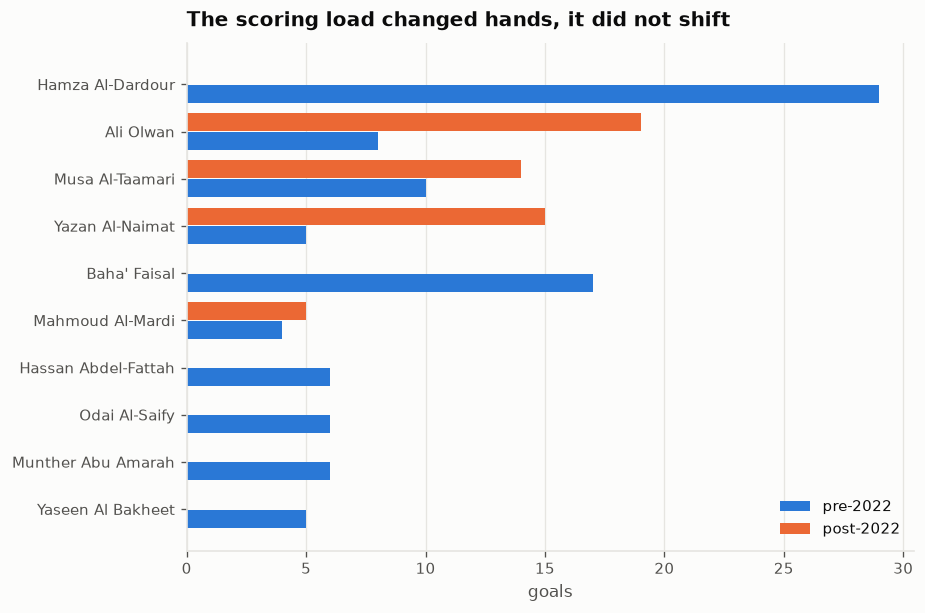

In [3]:
fig, ax = plt.subplots(figsize=(7.6, 5.0))
d = top.iloc[::-1]
y = np.arange(len(d))
ax.barh(y - 0.2, d.pre, height=0.38, color=viz.BLUE, label="pre-2022")
ax.barh(y + 0.2, d.post, height=0.38, color=viz.ORANGE, label="post-2022")
ax.set_yticks(y)
ax.set_yticklabels(d.player)
ax.set_xlabel("goals")
ax.set_title("The scoring load changed hands, it did not shift")
ax.legend(loc="lower right")
viz.despine(ax)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
plt.show()

**Plotted:** the same ten players, same order, two different questions.
**Left:** the share of *all* Jordan minutes each took, before and after — how
much they played. **Right:** goals per 90 minutes — how fast they scored. A
player who moved right on the left panel but not the right was simply picked
more. Blank on the right means under 270 minutes in that era, where a per-90 is
noise.

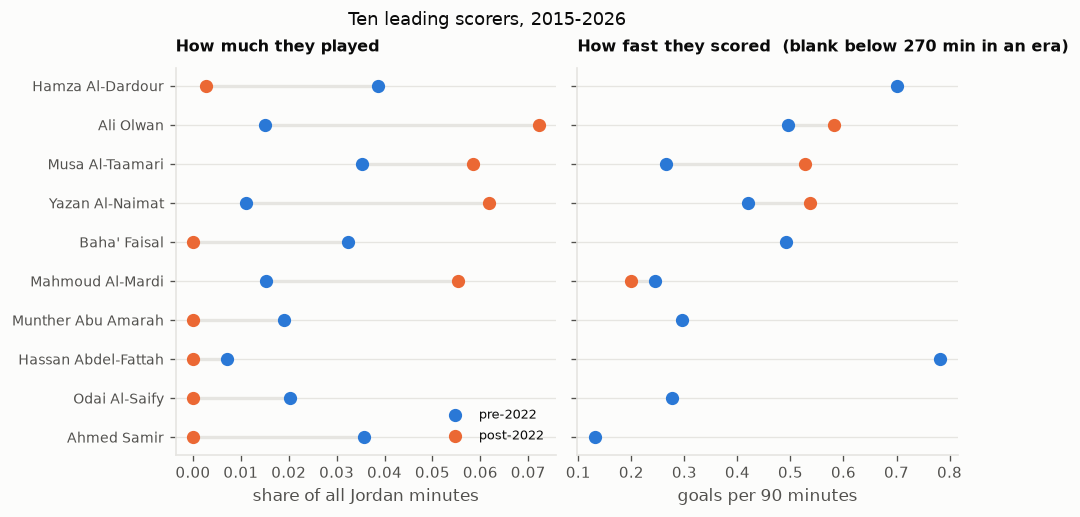

In [4]:
d = TOP.iloc[::-1]
y = np.arange(len(d))
fig, axes = plt.subplots(1, 2, figsize=(8.0, 4.2), sharey=True)
a = axes[0]
for i, r in enumerate(d.itertuples()):
    a.plot([r.share_min_pre, r.share_min_post], [i, i], color=viz.GRID, lw=2.0,
           zorder=1, solid_capstyle="round")
a.scatter(d.share_min_pre, y, color=viz.BLUE, s=48, zorder=3, label="pre-2022")
a.scatter(d.share_min_post, y, color=viz.ORANGE, s=48, zorder=3, label="post-2022")
a.set_yticks(y)
a.set_yticklabels(d.name, fontsize=8.5)
a.set_xlabel("share of all Jordan minutes")
a.set_title("How much they played", fontsize=9.5)
a.legend(fontsize=8, loc="lower right")
viz.despine(a)

b = axes[1]
for i, r in enumerate(d.itertuples()):
    if np.isfinite(r.p90_pre) and np.isfinite(r.p90_post):
        b.plot([r.p90_pre, r.p90_post], [i, i], color=viz.GRID, lw=2.0, zorder=1)
b.scatter(d.p90_pre, y, color=viz.BLUE, s=48, zorder=3)
b.scatter(d.p90_post, y, color=viz.ORANGE, s=48, zorder=3)
b.set_xlabel("goals per 90 minutes")
b.set_title(f"How fast they scored  (blank below {MIN_FLOOR} min in an era)",
            fontsize=9.5)
viz.despine(b)
fig.suptitle("Ten leading scorers, 2015-2026", fontsize=11)
plt.show()

**Plotted:** every player with at least three matches in that era — his share of
Jordan's minutes (x) against his share of Jordan's goals (y), one panel per era.
On the dashed diagonal a player takes exactly the share of the goals that he
takes of the time; above it he does more with what he gets. The four biggest
scorers in each era are named.

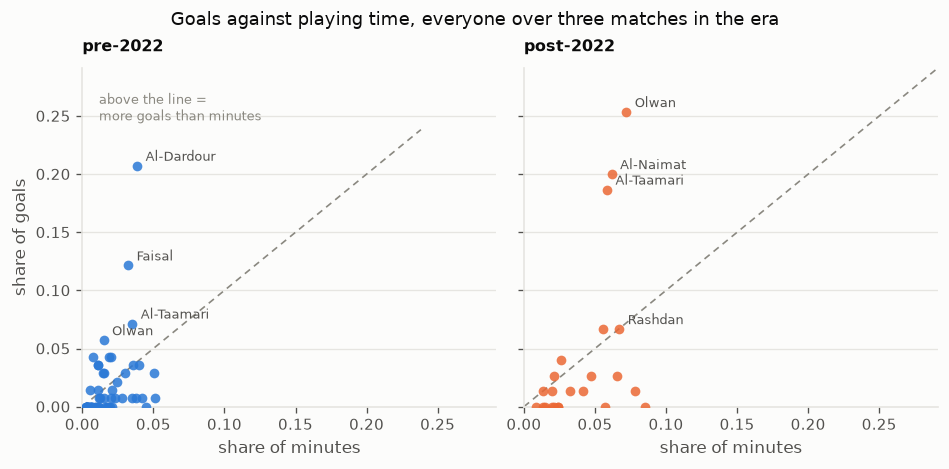

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.8), sharex=True, sharey=True)
for ax, e, col in ((axes[0], "pre", viz.BLUE), (axes[1], "post", viz.ORANGE)):
    d = sc[sc[e] >= MIN_FLOOR]
    lim = max(d[f"share_min_{e}"].max(), d[f"share_gls_{e}"].max()) * 1.15
    ax.plot([0, lim], [0, lim], color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)),
            zorder=1)
    ax.scatter(d[f"share_min_{e}"], d[f"share_gls_{e}"], s=34, color=col,
               alpha=0.85, zorder=3, linewidths=0)
    for r in d.sort_values(f"share_gls_{e}", ascending=False).head(4).itertuples():
        ax.annotate(getattr(r, "name").split()[-1],
                    (getattr(r, f"share_min_{e}"), getattr(r, f"share_gls_{e}")),
                    xytext=(5, 3), textcoords="offset points", fontsize=7.5,
                    color=viz.INK_2)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("share of minutes")
    ax.set_title(f"{e}-2022", fontsize=9.5)
    viz.despine(ax)
axes[0].set_ylabel("share of goals")
axes[0].annotate("above the line =" + chr(10) + "more goals than minutes",
                 xy=(0.04, 0.93), xycoords="axes fraction", fontsize=7.5,
                 color=viz.INK_MUTED, va="top")
fig.suptitle("Goals against playing time, everyone over three matches in the era",
             fontsize=10.5)
plt.show()

**They were picked far more, and they also got better.** Both halves matter, and
they are different claims.

Ali Olwan goes from **1.5% to 7.2%** of Jordan's minutes and Al-Naimat from 1.1%
to 6.2% — roughly five times the playing time each. That is selection. But the
rate moved too: **Al-Taamari doubles, 0.27 → 0.53 goals per 90**, and Olwan and
Al-Naimat both improve on an already decent number. Mahmoud Al-Mardi is the
counter-example, taking a large share of the minutes while his rate drifts down.

🚨 **The two panels are not interchangeable.** The share-of-goals view is
*compositional* — shares sum to one, so if one player's rises another's must
fall, and it can only say who took a bigger slice. Goals per 90 is *absolute* and
can say somebody actually got better. Al-Taamari's rate doubling exists only in
the second.

### 1.5 Where on the pitch — and a trap that nearly cost a finding

**Plotted, left:** the share of open-play goals scored by forwards, midfielders
and defenders, where each scorer is classified by his **modal** position across
his whole record. **Right:** the same single measure — midfield share of
open-play goals — asked two ways: by the label on that match's team sheet, and by
the player's usual position. The gap between the two numbers is the artefact.

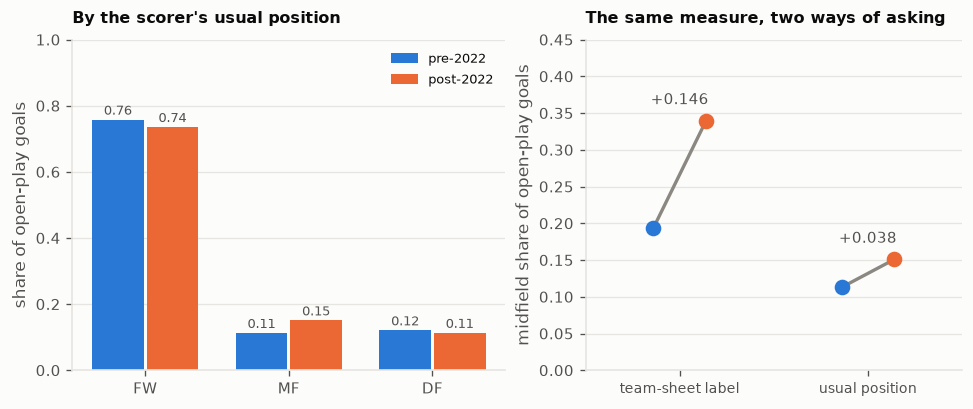

In [6]:
# scorer_position is the position on THAT MATCH'S team sheet, not the player's
# role (notebook 01, section 5). Ali Olwan, a striker, supplies five of the
# eighteen post-2022 "midfield" open-play goals. Classify instead by each
# scorer's modal position across his whole record.
_ja = ja.dropna(subset=["player_id"])
MODAL = _ja.groupby("player_id").Pos.agg(
    lambda s: s.mode().iloc[0] if s.notna().any() else None)
BAND = {"GK": "GK", "CB": "DF", "LB": "DF", "RB": "DF", "DF": "DF",
        "LWB": "DF", "RWB": "DF", "SW": "DF", "DM": "MF", "CM": "MF",
        "AM": "MF", "MF": "MF", "LM": "MF", "RM": "MF"}
band = lambda p: BAND.get(str(p).split(",")[0], "FW") if pd.notna(p) else None
op = gj[~gj.type.eq("penalty_goal")].copy()
op["modal_band"] = op.scorer_player_id.map(MODAL).map(band)
op = op.dropna(subset=["modal_band", "scorer_position"])

fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.3),
                         gridspec_kw={"width_ratios": [1.15, 1]})
a = axes[0]
pos = (pd.crosstab(op.modal_band, op.era, normalize="columns")
       .reindex(columns=["pre", "post"]).reindex(["FW", "MF", "DF"]).fillna(0))
x = np.arange(len(pos))
for off, e, col in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
    a.bar(x + off, pos[e], width=0.36, color=col, label=f"{e}-2022")
    for xi_, v in zip(x + off, pos[e]):
        a.annotate(f"{v:.2f}", (xi_, v), xytext=(0, 3), ha="center",
                   textcoords="offset points", fontsize=7.5, color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(pos.index)
a.set_ylim(0, 1.0)
a.set_ylabel("share of open-play goals")
a.set_title("By the scorer's usual position", fontsize=9.5)
a.legend(fontsize=8)
viz.despine(a)

b = axes[1]
lab = (pd.crosstab(op.scorer_position, op.era, normalize="columns")
       .reindex(columns=["pre", "post"]).reindex(["FW", "MF", "DF"]).fillna(0))
for i_, (nm, t_) in enumerate((("team-sheet label", lab), ("usual position", pos))):
    v = [t_.loc["MF", "pre"], t_.loc["MF", "post"]]
    b.plot([i_ - 0.14, i_ + 0.14], v, color=viz.INK_MUTED, lw=2.0, zorder=1)
    b.scatter([i_ - 0.14], [v[0]], color=viz.BLUE, s=70, zorder=3)
    b.scatter([i_ + 0.14], [v[1]], color=viz.ORANGE, s=70, zorder=3)
    b.annotate(f"{v[1] - v[0]:+.3f}", (i_, max(v)), xytext=(0, 10), ha="center",
               textcoords="offset points", fontsize=9, color=viz.INK_2)
b.set_xticks([0, 1])
b.set_xticklabels(["team-sheet label", "usual position"], fontsize=8.5)
b.set_xlim(-0.5, 1.5)
b.set_ylim(0, 0.45)
b.set_ylabel("midfield share of open-play goals")
b.set_title("The same measure, two ways of asking", fontsize=9.5)
viz.despine(b)
b.grid(axis="x", visible=False)
plt.show()

🚨 **The midfield finding was a labelling artefact, and it is retired.** It had
been reported as supported, with an interval. Ali Olwan — a striker on every
other measure — supplies **five of the eighteen** post-2022 midfield open-play
goals, and ten of the eighteen come from men whose usual position is forward.

| MF share of open-play goals | pre | post | change |
|---|---|---|---|
| team-sheet label | 0.194 | 0.340 | **+0.146** |
| scorer's usual position | 0.113 | 0.151 | **+0.038** |

Forwards are flat on the honest measure too — 0.758 → 0.736, a change of
**−0.022** against the **−0.146** the labels imply. **Nothing moved between the
lines.**

The composition half of the old story was the same relabelling counted twice: by
usual position the post-2022 XI carries *fewer* midfielders, 0.27 → 0.23 of the
outfield, and more defenders. "A back three puts more midfielders on the pitch,
so more midfield goals" was one recording change, told twice.

Notebook 02's split-date sweep had already flagged this measure as the only one
that could not locate a date — as large at a 2018 cut as at 2022. **That guard
fired before the data check did.** Take it seriously next time.

**Set-piece detail cannot rescue this section.** The event feed carries only
`goal / penalty_goal / own_goal / sub / yellow / red`, so "how many from corners
and free kicks" is not answerable from any source here. Penalties are the one
split available, and they are flat: 9.9% → 14.3% of goals, on 14 and 11 goals —
an interval far too wide to call a change.

## Part 2 — how few?

Three measurements of one question, each correcting a different flaw in the
obvious answer. The obvious answer — *Jordan used 16 scorers after 2022 and 32
before* — is wrong, because the post era has 75 goals against 182. **Richness
rises with sample size no matter what the underlying diversity is** (Hurlbert
1971).

The correction is **rarefaction** (Gotelli & Colwell 2001): repeatedly draw 75
goals from the pre-2022 era and see what a pre-2022 sample *of the same size*
looks like.

In [7]:
pre_s = gj[gj.era == "pre"].scorer_player_id
post_s = gj[gj.era == "post"].scorer_player_id
n_post = len(post_s)


def profile(s):
    vc = s.value_counts()
    p = vc / vc.sum()
    return np.array([len(vc), p.iloc[0], p.head(3).sum(), (p ** 2).sum()])


obs = profile(post_s)
draws = np.array([profile(pre_s.sample(n_post, replace=False,
                                       random_state=int(rng.integers(1e9))))
                  for _ in range(4000)])
LABELS = ["distinct scorers", "top-1 share", "top-3 share", "HHI"]
rows = []
for i, lab in enumerate(LABELS):
    lo, hi = np.percentile(draws[:, i], [2.5, 97.5])
    rows.append({"measure": lab, "post": obs[i], "pre_lo": lo, "pre_hi": hi,
                 "verdict": "outside" if not (lo <= obs[i] <= hi) else "inside"})
rar = pd.DataFrame(rows)
RAR_N = (n_post, int(obs[0]), len(pre_s), pre_s.nunique())

**Plotted:** four concentration measures in four different units, put on one axis
by expressing each post-2022 value in units of **its own rarefied pre-2022
range** — 0 is that range's floor, 1 its ceiling. A dot inside the grey band is
indistinguishable from a pre-2022 sample of the same size; orange is outside.

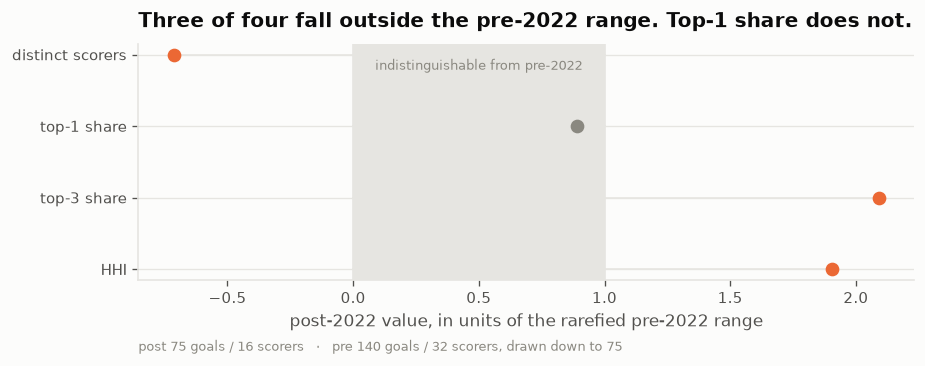

In [8]:
fig, ax = plt.subplots(figsize=(7.6, 2.9))
d = rar.iloc[::-1].reset_index(drop=True)
z = (d.post - d.pre_lo) / (d.pre_hi - d.pre_lo)
ax.axvspan(0, 1, color=viz.GRID, zorder=0)
ax.annotate("indistinguishable from pre-2022", xy=(0.5, 1.0),
            xycoords=("data", "axes fraction"), xytext=(0, -9),
            textcoords="offset points", ha="center", va="top", fontsize=8,
            color=viz.INK_MUTED)
for i, (v, verdict) in enumerate(zip(z, d.verdict)):
    col = viz.ORANGE if verdict == "outside" else viz.INK_MUTED
    ax.plot([min(v, 0), max(v, 1)], [i, i], color=viz.GRID, lw=1.0, zorder=1)
    ax.scatter([v], [i], color=col, s=52, zorder=3)
ax.set_yticks(range(len(d)))
ax.set_yticklabels(d.measure)
ax.set_xlabel("post-2022 value, in units of the rarefied pre-2022 range")
ax.set_title("Three of four fall outside the pre-2022 range. Top-1 share does not.")
ax.annotate(f"post {RAR_N[0]} goals / {RAR_N[1]} scorers   ·   "
            f"pre {RAR_N[2]} goals / {RAR_N[3]} scorers, drawn down to {RAR_N[0]}",
            xy=(0, -0.30), xycoords="axes fraction", fontsize=8,
            color=viz.INK_MUTED)
viz.despine(ax)
plt.show()

**Plotted:** the rarefaction curve itself — how many different scorers a random
sample of *k* goals yields, in each era, with a 95% band. The vertical line marks
the post-2022 total, the only place the two curves can be honestly compared. The
post curve sitting below the pre curve *at every k* is the finding.

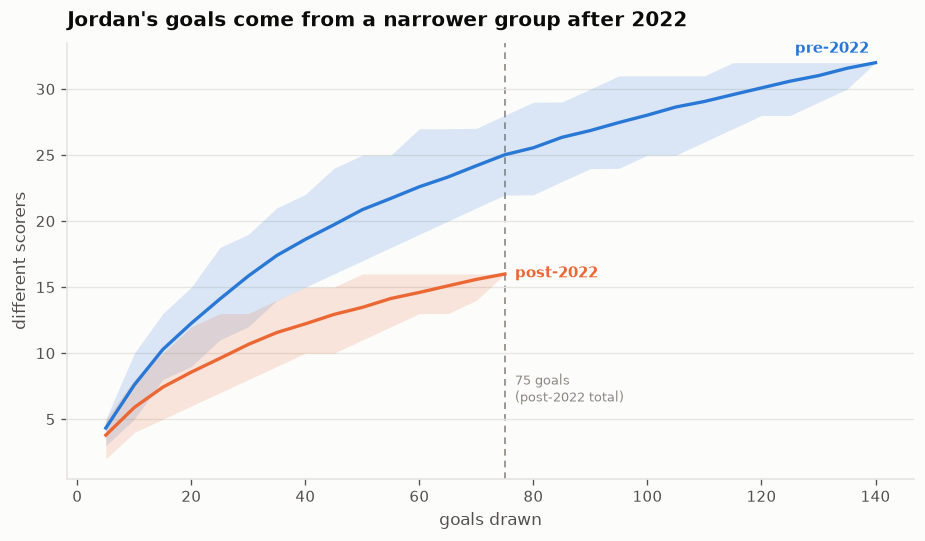

In [9]:
def curve(s, ks, reps=400):
    out = []
    for k in ks:
        if k > len(s):
            out.append((np.nan, np.nan, np.nan))
            continue
        v = [s.sample(k, replace=False,
                      random_state=int(rng.integers(1e9))).nunique()
             for _ in range(reps)]
        out.append((np.mean(v), *np.percentile(v, [2.5, 97.5])))
    return np.array(out)


ks = np.arange(5, len(pre_s) + 1, 5)
c_pre = curve(pre_s, ks)
ks_post = np.arange(5, n_post + 1, 5)
c_post = curve(post_s, ks_post)

fig, ax = plt.subplots(figsize=(7.6, 4.4))
ax.fill_between(ks, c_pre[:, 1], c_pre[:, 2], color=viz.BLUE, alpha=0.16, lw=0)
ax.plot(ks, c_pre[:, 0], color=viz.BLUE, label="pre-2022")
ax.fill_between(ks_post, c_post[:, 1], c_post[:, 2], color=viz.ORANGE,
                alpha=0.16, lw=0)
ax.plot(ks_post, c_post[:, 0], color=viz.ORANGE, label="post-2022")
ax.axvline(n_post, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=0)
ax.annotate(f"{n_post} goals" + chr(10) + "(post-2022 total)", xy=(n_post, 6),
            xytext=(6, 0), textcoords="offset points", fontsize=8,
            color=viz.INK_MUTED, va="bottom")
ax.annotate("pre-2022", xy=(ks[-1], c_pre[-1, 0]), xytext=(-4, 6),
            textcoords="offset points", color=viz.BLUE, fontsize=9,
            ha="right", fontweight="bold")
ax.annotate("post-2022", xy=(ks_post[-1], c_post[-1, 0]), xytext=(6, -2),
            textcoords="offset points", color=viz.ORANGE, fontsize=9,
            fontweight="bold")
ax.set_xlabel("goals drawn")
ax.set_ylabel("different scorers")
ax.set_title("Jordan's goals come from a narrower group after 2022")
viz.despine(ax)
plt.show()

**Plotted:** the third correction. Rarefaction fixed the *goal* count; this fixes
the *player* count — allocate each era's goals across players in proportion to
the minutes they actually played, and ask how much more concentrated the real
scoring is than that. Orange is observed, grey with a bar is what the minutes
imply; `×` is the ratio between them. **If the ratio is the same in both eras,
the narrowing belongs to notebook 03's squad, not to scoring.**

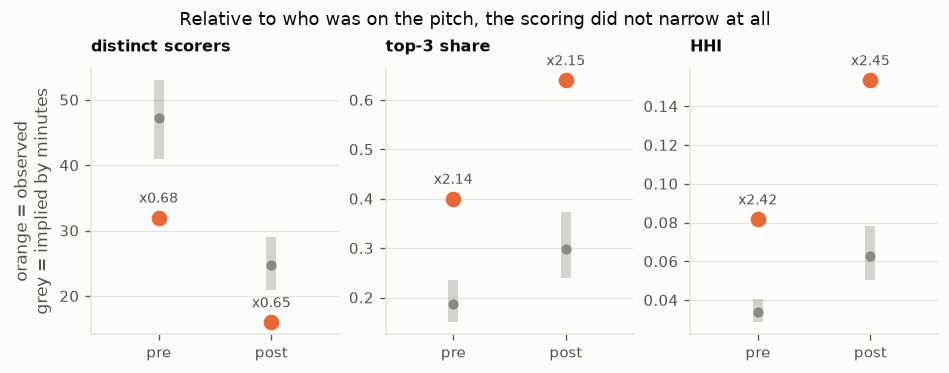

In [10]:
def gprofile(c):
    c = np.asarray(c, float)
    p = c[c > 0] / c[c > 0].sum()
    return {"distinct scorers": float(len(p)),
            "top-3 share": float(np.sort(p)[-3:].sum()),
            "HHI": float((p ** 2).sum())}


era_of = mt.set_index("match_id").era
jam = ja.assign(era=ja.match_id.map(era_of)).dropna(subset=["era"])
null = []
for e in ("pre", "post"):
    w = jam[jam.era == e].groupby("player_id").Min.sum()
    w = (w[w > 0] / w[w > 0].sum()).values
    g = gj[gj.era == e]
    obs_ = gprofile(g.scorer_player_id.value_counts().values)
    sim_ = pd.DataFrame([gprofile(rng.multinomial(len(g), w / w.sum()))
                         for _ in range(3000)])
    for k, v in obs_.items():
        lo, hi = np.percentile(sim_[k], [2.5, 97.5])
        null.append({"era": e, "measure": k, "observed": v,
                     "implied": sim_[k].mean(), "lo": lo, "hi": hi,
                     "ratio": v / sim_[k].mean()})
null = pd.DataFrame(null)

MEAS = ["distinct scorers", "top-3 share", "HHI"]
fig, axes = plt.subplots(1, 3, figsize=(7.8, 3.0))
for ax, k in zip(axes, MEAS):
    d = null[null.measure == k].set_index("era").reindex(["pre", "post"])
    x = np.arange(2)
    ax.vlines(x, d.lo, d.hi, color=viz.INK_MUTED, lw=6, alpha=0.35)
    ax.scatter(x, d.implied, color=viz.INK_MUTED, s=26, zorder=3)
    ax.scatter(x, d.observed, color=viz.ORANGE, s=70, zorder=4)
    for xi, r in zip(x, d.ratio):
        ax.annotate(f"x{r:.2f}", (xi, d.observed.iloc[xi]), xytext=(0, 9),
                    ha="center", textcoords="offset points", fontsize=8.5,
                    color=viz.INK_2)
    ax.set_xticks(x)
    ax.set_xticklabels(["pre", "post"])
    ax.set_xlim(-0.6, 1.6)
    ax.set_title(k, fontsize=9.5)
    viz.despine(ax)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("orange = observed" + chr(10) + "grey = implied by minutes")
fig.suptitle("Relative to who was on the pitch, the scoring did not narrow at all",
             fontsize=11)
plt.show()

**The old top two disappear** — Al-Dardour (29 goals, then 0) and Baha' Faisal
(17, then 0), not reduced roles but zero. **The new top three were already
scoring before 2022** and then roughly double or triple: Olwan 8 → 19, Al-Naimat
5 → 15, and Al-Taamari is in the top three of *both* eras (10 → 14). A wide
distribution collapsing onto three players who were already in it — not a new
generation arriving.

At any common number of goals the post era uses fewer scorers, and that is real.

🚨 **But it is not one man.** Top-1 share is 0.253 against a rarefied [0.147,
0.267] — *inside* the range. The popular version of this claim is **not
supportable**. The breadth measures move and the single-player measure does not;
that is a narrowing onto a small *group*.

🚨 **And the narrowing is not a fact about scoring.** Relative to the minutes
actually played, Jordan's scoring is about **2.4× more concentrated than the
minutes imply — the same multiple before and after 2022**. The distribution's
shape did not change. What changed is how few men were on the pitch, and how good
the few were. That is notebook 03's finding arriving here in a different costume.

## Part 3 — when, and in what state

Not who scored but *when*, and what the scoreboard said at the time.
Reconstructed by `match_state.py` from goal minutes on **both** sides, including
the ten Arab Cup matches Wikipedia supplied — without which the covered subset
was not representative (notebook 01, section 8).

In [11]:
ms = pd.read_csv(SQUAD / "match_state.csv", parse_dates=["date"])
ms = ms[(ms.date >= START) & ms.jordan_side.notna()].copy()
ms["era"] = np.where(ms.date < CUT, "pre", "post")
BUCK = ["1-15", "16-30", "31-45", "46-60", "61-75", "76-90"]
f_tot = ms[[f"for_{b}" for b in BUCK]].sum().values
a_tot = ms[[f"against_{b}" for b in BUCK]].sum().values
prof = pd.DataFrame({"window": BUCK, "scored": f_tot / f_tot.sum(),
                     "conceded": a_tot / a_tot.sum()})
MS_N = (len(ms), int(f_tot.sum()), int(a_tot.sum()))

**Plotted:** the share of Jordan's goals — scored and conceded separately —
falling in each fifteen-minute window. The dashed line is the all-football
benchmark for the 76–90 window from **Armatas et al. (2009)**, who find goals
rising steadily through a match and peaking at 22.5% there. Shares within each
column sum to one, so the two columns are read against the benchmark, not
against each other.

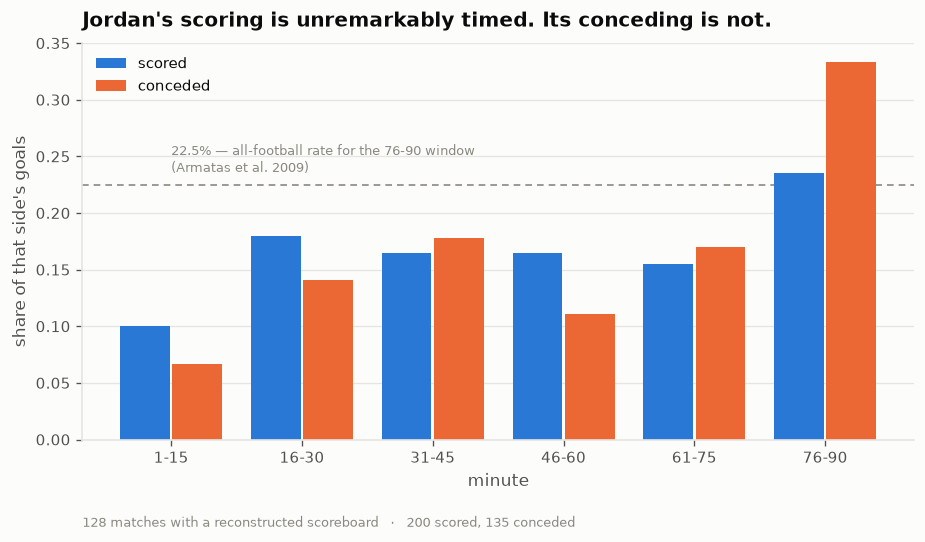

In [12]:
fig, ax = plt.subplots(figsize=(7.6, 4.4))
x = np.arange(len(BUCK))
ax.bar(x - 0.2, prof.scored, width=0.38, color=viz.BLUE, label="scored")
ax.bar(x + 0.2, prof.conceded, width=0.38, color=viz.ORANGE, label="conceded")
ax.axhline(0.225, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=0)
ax.annotate("22.5% — all-football rate for the 76-90 window" + chr(10)
            + "(Armatas et al. 2009)", xy=(0, 0.225), xytext=(0, 5),
            textcoords="offset points", fontsize=8, color=viz.INK_MUTED,
            va="bottom")
ax.set_xticks(x)
ax.set_xticklabels(BUCK)
ax.set_xlabel("minute")
ax.set_ylabel("share of that side's goals")
ax.set_title("Jordan's scoring is unremarkably timed. Its conceding is not.")
ax.annotate(f"{MS_N[0]} matches with a reconstructed scoreboard   ·   "
            f"{MS_N[1]} scored, {MS_N[2]} conceded",
            xy=(0, -0.22), xycoords="axes fraction", fontsize=8,
            color=viz.INK_MUTED)
ax.legend(loc="upper left")
viz.despine(ax)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", visible=True)
plt.show()

Jordan's scoring sits on the all-football benchmark — the attack has no special
relationship with the clock. **The conceding column is the outlier: a third of
every goal Jordan concedes arrives in the last fifteen minutes**, about half
again what Armatas et al. expect.

This describes all 155 matches, **not** a change across 2022 — the era difference
does not clear zero. A standing feature, and the clearest thing in this project
pointing at something to fix.

### 3.2 Crossing *when* with *in what state*

"A third of goals conceded arrive after the 75th" fits two opposite stories: a
team that throws away leads, or one that gets put away in matches it was already
losing. Neither section settles it alone. **Crossing them does.**

Rates need **minutes at risk** per cell, not goal counts — a team that spends the
last fifteen minutes level has more chance to concede a level-state goal simply
by being there.

In [13]:
cells = pd.read_csv(SQUAD / "state_time_cells.csv")
cells = cells[cells.match_id.isin(set(mt.match_id))]          # 2015+ window
grid = (cells.groupby(["window", "state"])
        .agg(minutes=("minutes", "sum"), ga=("ga", "sum"), gf=("gf", "sum"))
        .reset_index())
grid["conceded_per90"] = grid.ga / grid.minutes * 90
grid["scored_per90"] = grid.gf / grid.minutes * 90
ORDER = ["1-15", "16-30", "31-45", "46-60", "61-75", "76-90"]

**Plotted, top:** goals conceded per 90 minutes *at risk*, one line per
scoreboard state. **Bottom:** the denominator those rates are built on — minutes
Jordan actually spent leading, level and trailing in each window. A rate is a
fraction, so both halves are drawn; the late level cell is the smallest
denominator on the chart, which is why its interval is wide.

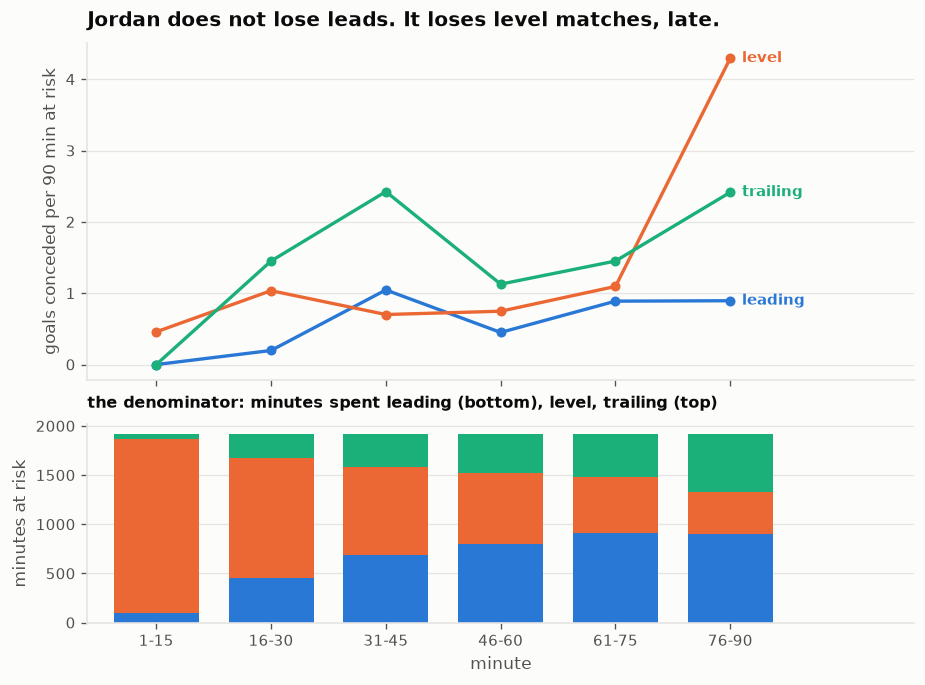

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(7.6, 5.6), sharex=True,
                         gridspec_kw={"height_ratios": [1.7, 1]})
x = np.arange(len(ORDER))
STATES = (("leading", viz.BLUE), ("level", viz.ORANGE), ("trailing", viz.AQUA))
a = axes[0]
for st, col in STATES:
    y = grid[grid.state == st].set_index("window").reindex(ORDER).conceded_per90
    a.plot(x, y.values, color=col, marker="o", label=st)
    a.annotate(st, xy=(x[-1], y.values[-1]), xytext=(7, 0),
               textcoords="offset points", color=col, fontsize=9,
               va="center", fontweight="bold")
a.set_ylabel("goals conceded per 90 min at risk")
a.set_title("Jordan does not lose leads. It loses level matches, late.")
viz.despine(a)

b = axes[1]
bot = np.zeros(len(ORDER))
for st, col in STATES:
    m_ = grid[grid.state == st].set_index("window").reindex(ORDER).minutes.fillna(0).values
    b.bar(x, m_, bottom=bot, width=0.74, color=col, label=st)
    bot = bot + m_
b.set_xticks(x)
b.set_xticklabels(ORDER)
b.set_xlim(-0.6, len(ORDER) + 0.6)
b.set_xlabel("minute")
b.set_ylabel("minutes at risk")
b.set_title("the denominator: minutes spent leading (bottom), level, trailing (top)",
            fontsize=9.5)
viz.despine(b)
plt.show()

The blue line is **the control, and it is flat**: with a lead, Jordan's conceding
rate in the last fifteen minutes is indistinguishable from the fifteen before it.
Leads are not the problem. The orange line is the finding.

**Plotted, left:** the 76–90 conceding rate as a *multiple* of the 61–75 rate,
with a block-bootstrap interval, for the two states that matter. Log axis; 1×
means no late effect. **Right:** the internal control — Jordan's own scoring and
conceding rates while level, going into the same window. If level matches simply
got frantic both lines would rise.

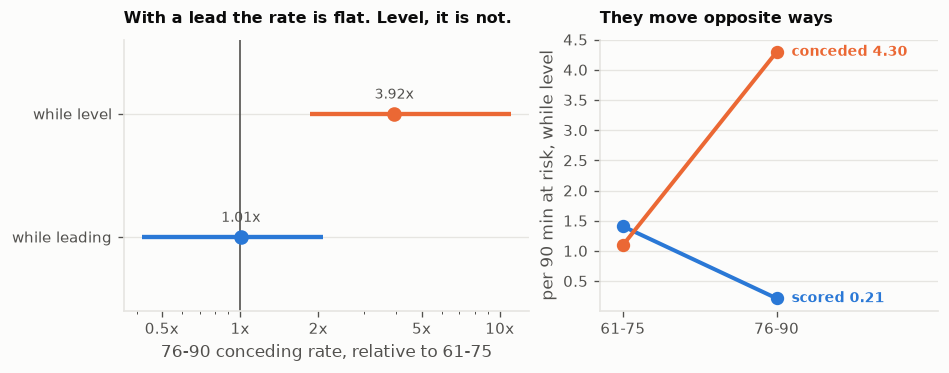

In [15]:
by_match = {m: d for m, d in cells.groupby("match_id")}
blocks = [d.match_id.tolist() for _, d in mt.groupby("blk")]


def rate(ms_, window, state, direction="ga"):
    d = pd.concat([by_match[m] for m in ms_ if m in by_match])
    s = d[(d.window == window) & (d.state == state)]
    return s[direction].sum() / s.minutes.sum() * 90 if s.minutes.sum() > 0 else np.nan


def ratio(ms_, state):
    late, before = rate(ms_, "76-90", state), rate(ms_, "61-75", state)
    return late / before if before and np.isfinite(before) else np.nan


ALL_M = mt.match_id.tolist()
ratios = []
for st in ("leading", "level"):
    obs_ = ratio(ALL_M, st)
    dr = []
    for _ in range(1500):
        pick = [m for i in rng.integers(0, len(blocks), len(blocks)) for m in blocks[i]]
        v = ratio(pick, st)
        if np.isfinite(v):
            dr.append(v)
    lo, hi = np.percentile(dr, [2.5, 97.5])
    ratios.append({"state": st, "obs": obs_, "lo": lo, "hi": hi})
ratios = pd.DataFrame(ratios)

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.0),
                         gridspec_kw={"width_ratios": [1.2, 1]})
a = axes[0]
for i, r in ratios.iterrows():
    col = viz.ORANGE if r.lo > 1 else viz.BLUE
    a.hlines(i, r.lo, r.hi, color=col, lw=2.6)
    a.scatter([r.obs], [i], color=col, s=60, zorder=3)
    a.annotate(f"{r.obs:.2f}x", (r.obs, i), xytext=(0, 9), ha="center",
               textcoords="offset points", fontsize=8.5, color=viz.INK_2)
a.axvline(1.0, color=viz.INK_2, lw=1.0)
a.set_xscale("log")
a.set_xticks([0.5, 1, 2, 5, 10])
a.set_xticklabels(["0.5x", "1x", "2x", "5x", "10x"])
a.set_yticks(range(len(ratios)))
a.set_yticklabels([f"while {v}" for v in ratios.state])
a.set_ylim(-0.6, len(ratios) - 0.4)
a.set_xlabel("76-90 conceding rate, relative to 61-75")
a.set_title("With a lead the rate is flat. Level, it is not.", fontsize=9.5)
viz.despine(a)

b = axes[1]
for lab, direction, col in (("scored", "gf", viz.BLUE),
                            ("conceded", "ga", viz.ORANGE)):
    v = [rate(ALL_M, w, "level", direction) for w in ("61-75", "76-90")]
    b.plot([0, 1], v, color=col, lw=2.4, marker="o", ms=7, label=lab)
    b.annotate(f"{lab} {v[1]:.2f}", (1, v[1]), xytext=(9, 0), va="center",
               textcoords="offset points", fontsize=8.5, color=col,
               fontweight="bold")
b.set_xticks([0, 1])
b.set_xticklabels(["61-75", "76-90"])
b.set_xlim(-0.15, 2.05)
b.set_ylabel("per 90 min at risk, while level")
b.set_title("They move opposite ways", fontsize=9.5)
viz.despine(b)
b.grid(axis="x", visible=False)
plt.show()

**While level: 3.92×, 95% [1.80, 11.47]. While leading: 1.01×, 95% [0.45,
2.22].** The control is what makes this more than "goals rise late" — Armatas
finds that everywhere, but a general effect would lift the leading row too, and
it does not.

🚨 **The internal control is the decisive one.** If level matches simply got
frantic, Jordan should score more late as well. It does the opposite: while
level, 61–75 → 76–90, scoring goes **1.41 → 0.21** per 90 while conceding goes
**1.10 → 4.30**. **Since 2015 Jordan has scored one goal while level in the last
fifteen minutes and conceded twenty.**

### 3.3 Two checks before trusting it

**Plotted:** the clock convention. Minutes at risk stop at 90 for every match
while stoppage time is always played, so the last window's rate is inflated — for
everyone. The curve shows what happens to the 76–90 : 61–75 ratio as stoppage
minutes are added back to every match still level at 90. Adding it can only
shrink the effect; the question is by how much.

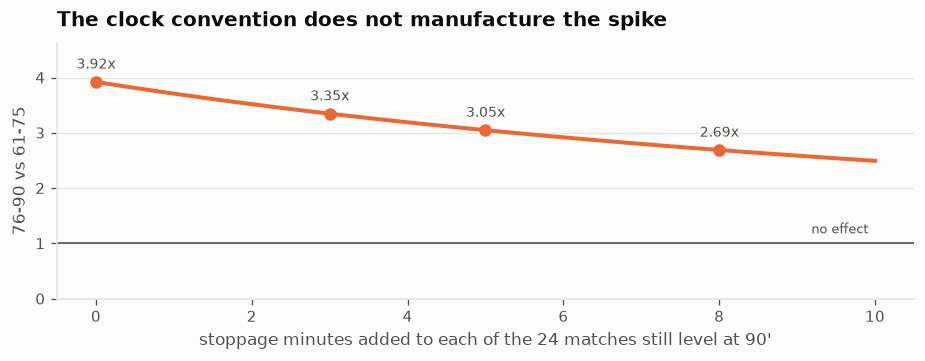

In [16]:
from match_state import goal_timelines
TL = {m: v for m, v in goal_timelines().items() if m in set(mt.match_id)}
info = mt.set_index("match_id")

level_at_90 = sum(1 for tl, _s, _x in TL.values()
                  if sum(d for m_, d in tl if m_ <= 90) == 0)
lvl = grid[grid.state == "level"].set_index("window")
extra = np.linspace(0, 10, 101)
mins_ = lvl.loc["76-90", "minutes"] + extra * level_at_90
curve_ = (lvl.loc["76-90", "ga"] / mins_ * 90) / lvl.loc["61-75", "conceded_per90"]

fig, ax = plt.subplots(figsize=(7.6, 2.9))
ax.plot(extra, curve_, color=viz.ORANGE, lw=2.4)
ax.axhline(1.0, color=viz.INK_2, lw=1.0)
ax.annotate("no effect", xy=(10, 1.0), xytext=(-4, 6), ha="right",
            textcoords="offset points", fontsize=8, color=viz.INK_2)
for e in (0, 3, 5, 8):
    v = (lvl.loc["76-90", "ga"] / (lvl.loc["76-90", "minutes"] + e * level_at_90)
         * 90) / lvl.loc["61-75", "conceded_per90"]
    ax.scatter([e], [v], color=viz.ORANGE, s=42, zorder=3)
    ax.annotate(f"{v:.2f}x", (e, v), xytext=(0, 8), ha="center",
                textcoords="offset points", fontsize=8.5, color=viz.INK_2)
ax.set_ylim(0, max(curve_) * 1.18)
ax.set_xlabel(f"stoppage minutes added to each of the {level_at_90} matches "
              f"still level at 90'")
ax.set_ylabel("76-90 vs 61-75")
ax.set_title("The clock convention does not manufacture the spike")
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

**Plotted:** the second check, independent of the rate arithmetic entirely. Every
match Jordan reached the 75th minute level in, by how it finished — win, draw or
loss — with the count inside each segment and points per match on the right. If
the rate story is real it should show up here as dropped points.

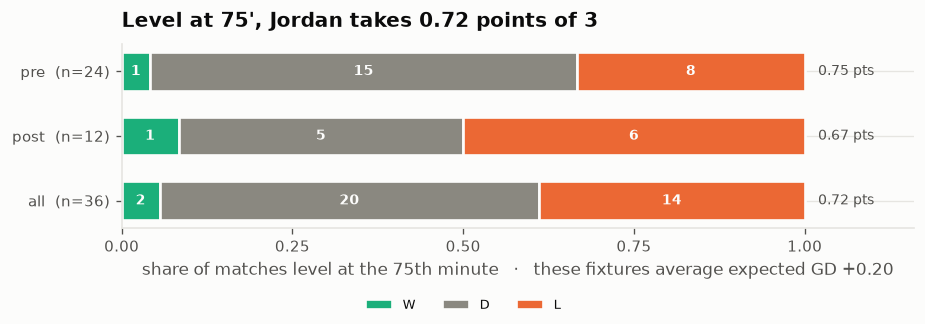

In [17]:
rows = []
for mid, (tl, _s, _x) in TL.items():
    if sum(d for m_, d in tl if m_ <= 75) != 0:      # level at 75' only
        continue
    dft = sum(d for _, d in tl)
    r = info.loc[mid]
    rows.append({"match_id": mid, "date": r.date, "era": r.era,
                 "opponent": r.opponent, "expected_gf": r.expected_gf,
                 "expected_ga": r.expected_ga, "expected_gd": r.expected_gd,
                 "blk": r.blk, "pts": 3 if dft > 0 else (1 if dft == 0 else 0),
                 "result": "W" if dft > 0 else ("D" if dft == 0 else "L")})
L = pd.DataFrame(rows)
wdl = (pd.crosstab(L.era, L.result).reindex(columns=["W", "D", "L"]).fillna(0)
       .astype(int).reindex(["pre", "post"]))
wdl.loc["all"] = wdl.sum()

fig, ax = plt.subplots(figsize=(7.6, 2.6))
y = np.arange(len(wdl))[::-1]
left = np.zeros(len(wdl))
for res, col in (("W", viz.AQUA), ("D", viz.INK_MUTED), ("L", viz.ORANGE)):
    v = wdl[res].values / wdl.sum(axis=1).values
    ax.barh(y, v, left=left, height=0.6, color=col, label=res,
            edgecolor=viz.SURFACE, linewidth=1.6)
    for yy, (frac, n_, l0) in enumerate(zip(v, wdl[res].values, left)):
        if n_:
            ax.annotate(str(n_), (l0 + frac / 2, y[yy]), ha="center", va="center",
                        fontsize=8.5, color=viz.SURFACE, fontweight="bold")
    left = left + v
for i, e in enumerate(wdl.index):
    d = L if e == "all" else L[L.era == e]
    ax.annotate(f"{d.pts.mean():.2f} pts", (1.0, y[i]), xytext=(8, 0),
                va="center", textcoords="offset points", fontsize=8.5,
                color=viz.INK_2)
ax.set_yticks(y)
ax.set_yticklabels([f"{e}  (n={int(n_)})"
                    for e, n_ in zip(wdl.index, wdl.sum(axis=1))])
ax.set_xlim(0, 1.16)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xlabel(f"share of matches level at the 75th minute   ·   these fixtures "
              f"average expected GD {L.expected_gd.mean():+.2f}")
ax.set_title(f"Level at 75', Jordan takes {L.pts.mean():.2f} points of 3")
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=3,
           fontsize=8)
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

**36 matches level at the 75th minute → 2W 20D 14L, 0.72 points of a possible
3.** That is the same finding arriving through results rather than rates, which
is the point of running it.

### 3.4 What is it worth, against these opponents?

These 36 fixtures average expected goal difference **+0.20** — Jordan was
*favoured* in them. So the shortfall has to be measured against what the model
thought a level scoreline at 75 minutes was worth here, not against three points.

**Plotted, left:** points per match actually taken from a level scoreline at 75',
against what the model expects — simulating the remaining fifteen minutes at each
fixture's own goal rates. **Right:** the difference, with a bootstrap interval,
and the total points it comes to across the 36 matches.

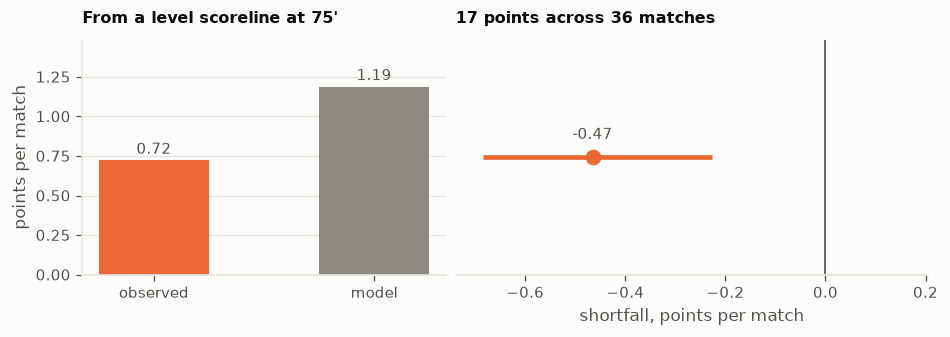

In [18]:
sim = []
for r in L.itertuples():
    kf = rng.poisson(r.expected_gf * 15 / 90, 40000)
    ka = rng.poisson(r.expected_ga * 15 / 90, 40000)
    d = kf - ka
    sim.append(np.where(d > 0, 3, np.where(d == 0, 1, 0)).mean())
sim = np.array(sim)
obs_p, exp_p = L.pts.mean(), sim.mean()
dr = [(L.pts.values[p].mean() - sim[p].mean())
      for p in (rng.integers(0, len(L), len(L)) for _ in range(5000))]
lo, hi = np.percentile(dr, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(7.8, 2.7),
                         gridspec_kw={"width_ratios": [1, 1.3]})
a = axes[0]
a.bar([0, 1], [obs_p, exp_p], width=0.5, color=[viz.ORANGE, viz.INK_MUTED])
for i, v in enumerate((obs_p, exp_p)):
    a.annotate(f"{v:.2f}", (i, v), xytext=(0, 4), ha="center",
               textcoords="offset points", fontsize=9, color=viz.INK_2)
a.set_xticks([0, 1])
a.set_xticklabels(["observed", "model"])
a.set_ylim(0, max(obs_p, exp_p) * 1.25)
a.set_ylabel("points per match")
a.set_title("From a level scoreline at 75'", fontsize=9.5)
viz.despine(a)

b = axes[1]
b.hlines(0, lo, hi, color=viz.ORANGE, lw=2.8)
b.scatter([obs_p - exp_p], [0], color=viz.ORANGE, s=70, zorder=3)
b.axvline(0, color=viz.INK_2, lw=1.0)
b.annotate(f"{obs_p - exp_p:+.2f}", (obs_p - exp_p, 0), xytext=(0, 11),
           ha="center", textcoords="offset points", fontsize=9, color=viz.INK_2)
b.set_ylim(-1, 1)
b.set_yticks([])
b.set_xlim(min(lo, 0) * 1.08, max(abs(lo), 0.05) * 0.30)
b.set_xlabel("shortfall, points per match")
b.set_title(f"{abs(obs_p - exp_p) * len(L):.0f} points across {len(L)} matches",
            fontsize=9.5)
viz.despine(b, keep=("bottom",))
plt.show()

A level scoreline at 75 minutes against these opponents should be worth about
**1.2 points**. Jordan takes **0.72** — roughly half a point per match short,
interval excluding zero, about **17 points** across 36 matches.

🚨 **But that number must not be quoted clean.** The simulation behind the 1.2
draws goals at a **constant rate whatever the scoreboard says**. The match-status
literature says that is wrong for exactly this situation: **Lago-Peñas &
Gómez-López (2014)** show match status drives possession and territory, and late
goals are more common when a match is level — everywhere, for everyone. Neither
that paper nor Armatas reports a late-goal rate conditioned on being level at the
75th specifically, so the size of the mis-specification has to come from Jordan's
own data.

### 3.5 What survives the mis-specification

**Plotted, left:** the model checked against these 36 matches on its own terms —
goals per match after the 75th, and the draw rate, observed against simulated.
Two different units side by side on purpose. **Right:** Jordan's *share* of the
goals scored after the 75th in these matches, with a bootstrap interval, against
the model-implied share and against an even split. A general "level matches are
busy late" effect predicts volume; it does not predict direction.

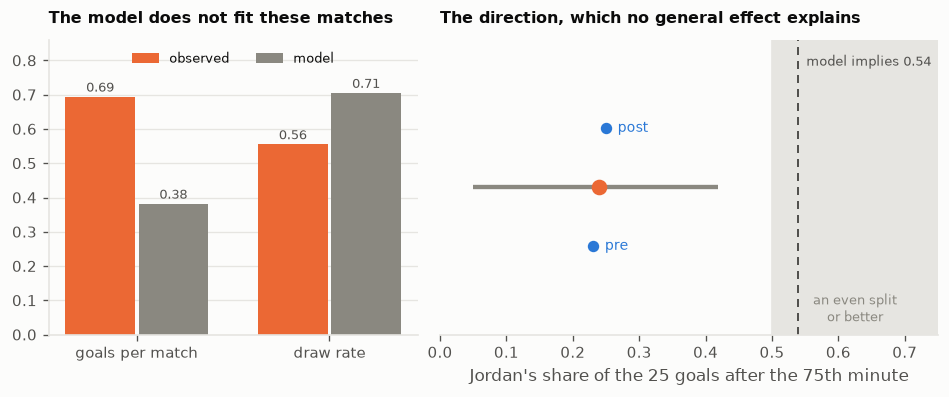

In [19]:
late = pd.DataFrame([{"match_id": m,
                      "gf75": sum(1 for x, d in TL[m][0] if x > 75 and d > 0),
                      "ga75": sum(1 for x, d in TL[m][0] if x > 75 and d < 0)}
                     for m in L.match_id]).merge(L, on="match_id")
sg, sd = [], []
for r in late.itertuples():
    kf = rng.poisson(r.expected_gf * 15 / 90, 40000)
    ka = rng.poisson(r.expected_ga * 15 / 90, 40000)
    sg.append((kf + ka).mean())
    sd.append((kf == ka).mean())

f_, g_ = int(late.gf75.sum()), int(late.ga75.sum())
sh = []
for _ in range(20000):
    d = late.sample(len(late), replace=True, random_state=int(rng.integers(1e9)))
    t = d.gf75.sum() + d.ga75.sum()
    if t:
        sh.append(d.gf75.sum() / t)
sh_lo, sh_hi = np.percentile(sh, [2.5, 97.5])
mdl = (late.expected_gf / (late.expected_gf + late.expected_ga)).mean()

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.2),
                         gridspec_kw={"width_ratios": [1, 1.35]})
a = axes[0]
x = np.arange(2)
obs_v = [(late.gf75 + late.ga75).mean(), (late.pts == 1).mean()]
mod_v = [np.mean(sg), np.mean(sd)]
for off, vals, col, lab in ((-0.19, obs_v, viz.ORANGE, "observed"),
                            (0.19, mod_v, viz.INK_MUTED, "model")):
    a.bar(x + off, vals, width=0.36, color=col, label=lab)
    for xi, v in zip(x + off, vals):
        a.annotate(f"{v:.2f}", (xi, v), xytext=(0, 3), textcoords="offset points",
                   ha="center", fontsize=8, color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(["goals per match", "draw rate"])
a.set_ylim(0, max(obs_v + mod_v) * 1.22)
a.set_title("The model does not fit these matches", fontsize=9.5)
a.legend(fontsize=8, loc="upper center", ncol=2)
viz.despine(a)

b = axes[1]
b.axvspan(0.5, 0.75, color=viz.GRID, zorder=0)
b.annotate("an even split" + chr(10) + "or better", xy=(0.625, 0.03),
           xycoords=("data", "axes fraction"), ha="center", va="bottom",
           fontsize=8, color=viz.INK_MUTED)
b.hlines(0, sh_lo, sh_hi, color=viz.INK_MUTED, lw=2.6)
b.scatter([f_ / (f_ + g_)], [0], color=viz.ORANGE, s=70, zorder=4)
for k, (e, yy) in enumerate((("pre", -0.8), ("post", 0.8))):
    dd = late[late.era == e]
    b.scatter([dd.gf75.sum() / (dd.gf75.sum() + dd.ga75.sum())], [yy],
              color=viz.BLUE, s=34, zorder=4)
    b.annotate(e, (dd.gf75.sum() / (dd.gf75.sum() + dd.ga75.sum()), yy),
               xytext=(7, 0), textcoords="offset points", fontsize=8.5,
               color=viz.BLUE, va="center")
b.axvline(mdl, color=viz.INK_2, lw=1.2, ls=(0, (4, 3)))
b.annotate(f"model implies {mdl:.2f}", (mdl, 1.0),
           xycoords=("data", "axes fraction"), xytext=(5, -9),
           textcoords="offset points", fontsize=8, color=viz.INK_2, va="top")
b.set_ylim(-2, 2)
b.set_yticks([])
b.set_xlim(0, 0.75)
b.set_xlabel(f"Jordan's share of the {f_ + g_} goals after the 75th minute")
b.set_title("The direction, which no general effect explains", fontsize=9.5)
viz.despine(b, keep=("bottom",))
plt.show()

🚨 **The model is visibly mis-specified for these matches.** It predicts **0.38**
goals per match after the 75th where **0.69** are observed, and **0.71** draws
where **0.56** happen. So part of the 3.92× and part of the −0.47 is general
football, not Jordan.

✅ **What survives is the DIRECTION, and it is the better finding.** Of the 25
goals after the 75th minute in those 36 matches, Jordan **scored 6 and conceded
19** — a share of **0.240, 95% [0.048, 0.419]**, excluding an even split, against
a **model-implied 0.539**. Stable across eras (pre 0.231 on 13 goals, post 0.250
on 12).

A busy last fifteen minutes in a level match is ordinary football. **Those goals
going one way three times in four, in fixtures the model makes Jordan the
favourite in, is not.** Lead with the direction; read the rate ratio and the
points shortfall as symptoms beneath it.

🚨 **Do not explain it.** The obvious reading — a team chasing a winner, caught on
the break — needs shot locations or possession to test, and neither exists for
these matches (notebook 01, section 4). It is a description of what happens, not
a mechanism.

### 3.6 Did any of this change across 2022?

**Plotted, left:** the conceding rate while level, going into the last window, by
era — the label on each bar gives the goals and the minutes at risk behind it.
**Right:** the era difference with its block-bootstrap interval. Ten goals in a
hundred-odd minutes distinguishes almost nothing, which is what the interval
says.

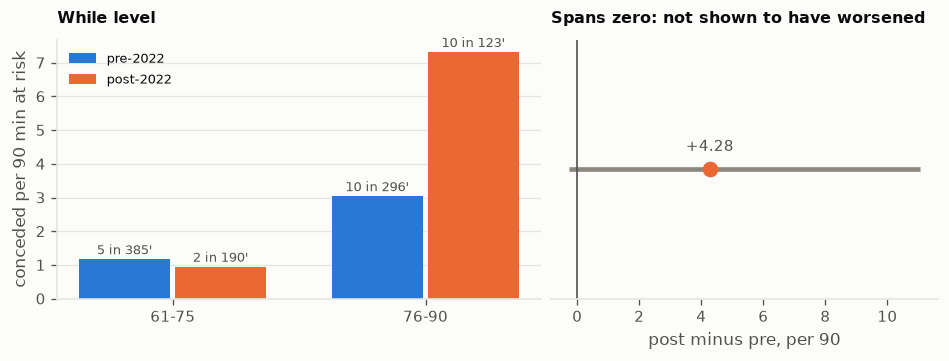

In [20]:
cells["era"] = cells.match_id.map(mt.set_index("match_id").era)
cellsum = []
for e in ("pre", "post"):
    d = cells[(cells.era == e) & (cells.state == "level")]
    for w in ("61-75", "76-90"):
        q = d[d.window == w]
        cellsum.append({"era": e, "window": w, "ga": int(q.ga.sum()),
                        "minutes": q.minutes.sum(),
                        "per90": q.ga.sum() / q.minutes.sum() * 90})
cellsum = pd.DataFrame(cellsum)


def late_level(ms_):
    return rate(ms_, "76-90", "level")


blk = {e: [d.match_id.tolist() for _, d in mt[mt.era == e].groupby("blk")]
       for e in ("pre", "post")}
dr = []
for _ in range(2000):
    s = {e: [m for i in rng.integers(0, len(blk[e]), len(blk[e])) for m in blk[e][i]]
         for e in ("pre", "post")}
    v = late_level(s["post"]) - late_level(s["pre"])
    if np.isfinite(v):
        dr.append(v)
lo, hi = np.percentile(dr, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(7.8, 2.9),
                         gridspec_kw={"width_ratios": [1.25, 1]})
a = axes[0]
x = np.arange(2)
for off, e, col in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
    d = cellsum[cellsum.era == e].set_index("window").reindex(["61-75", "76-90"])
    a.bar(x + off, d.per90.values, width=0.36, color=col, label=f"{e}-2022")
    for xi, (v, ga_, mn) in enumerate(zip(d.per90, d.ga, d.minutes)):
        a.annotate(f"{ga_} in {mn:.0f}'", (x[xi] + off, v), xytext=(0, 3),
                   ha="center", textcoords="offset points", fontsize=7.5,
                   color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(["61-75", "76-90"])
a.set_ylabel("conceded per 90 min at risk")
a.set_title("While level", fontsize=9.5)
a.legend(fontsize=8, loc="upper left")
viz.despine(a)
a.grid(axis="x", visible=False)

b = axes[1]
b.hlines(0, lo, hi, color=viz.INK_MUTED, lw=2.8)
dlate = late_level(mt[mt.era == "post"].match_id.tolist()) - \
    late_level(mt[mt.era == "pre"].match_id.tolist())
b.scatter([dlate], [0], color=viz.ORANGE, s=70, zorder=3)
b.annotate(f"{dlate:+.2f}", (dlate, 0), xytext=(0, 11), ha="center",
           textcoords="offset points", fontsize=9, color=viz.INK_2)
b.axvline(0, color=viz.INK_2, lw=1.0)
b.set_ylim(-1, 1)
b.set_yticks([])
b.set_xlabel("post minus pre, per 90")
b.set_title("Spans zero: not shown to have worsened", fontsize=9.5)
viz.despine(b, keep=("bottom",))
plt.show()

**Plotted:** the same era question in the interpretable unit — points per match
against the model's expectation, from a level scoreline at 75', for each era and
for the change between them. Every bar is a bootstrap interval.

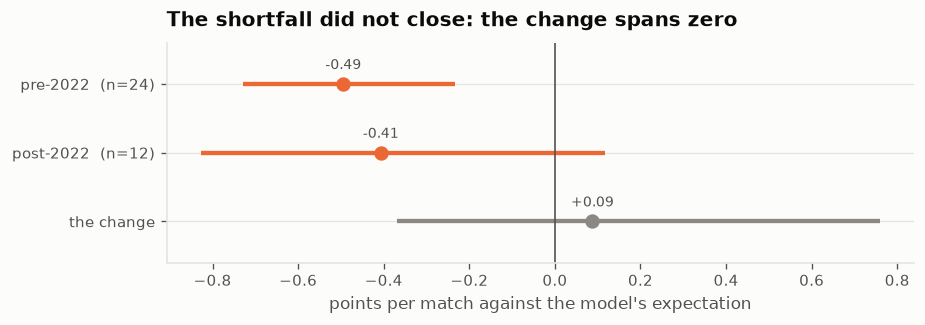

In [21]:
L["expected_pts"] = sim
L["short"] = L.pts - L.expected_pts
LB = {e: [d.match_id.tolist() for _, d in L[L.era == e].groupby("blk")]
      for e in ("pre", "post")}
lm = L.set_index("match_id")
d_obs = L[L.era == "post"].short.mean() - L[L.era == "pre"].short.mean()
dr = []
for _ in range(4000):
    s = {e: [m for i in rng.integers(0, len(LB[e]), len(LB[e])) for m in LB[e][i]]
         for e in ("pre", "post")}
    v = lm.loc[s["post"]].short.mean() - lm.loc[s["pre"]].short.mean()
    if np.isfinite(v):
        dr.append(v)
lo, hi = np.percentile(dr, [2.5, 97.5])
rows = []
for e in ("pre", "post"):
    d = L[L.era == e]
    bb = [d.short.values[p].mean()
          for p in (rng.integers(0, len(d), len(d)) for _ in range(5000))]
    l2, h2 = np.percentile(bb, [2.5, 97.5])
    rows.append({"row": f"{e}-2022  (n={len(d)})", "est": d.short.mean(),
                 "lo": l2, "hi": h2, "kind": "level"})
rows.append({"row": "the change", "est": d_obs, "lo": lo, "hi": hi,
             "kind": "change"})
short_era = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.6, 2.6))
d = short_era.iloc[::-1].reset_index(drop=True)
y = np.arange(len(d))
for i, r in d.iterrows():
    col = viz.INK_MUTED if r.kind == "change" else viz.ORANGE
    ax.hlines(i, r.lo, r.hi, color=col, lw=2.6)
    ax.scatter([r.est], [i], color=col, s=58, zorder=3)
    ax.annotate(f"{r.est:+.2f}", (r.est, i), xytext=(0, 9), ha="center",
                textcoords="offset points", fontsize=8.5, color=viz.INK_2)
ax.axvline(0, color=viz.INK_2, lw=1.0)
ax.set_yticks(y)
ax.set_yticklabels(d.row)
ax.set_ylim(-0.6, len(d) - 0.4)
ax.set_xlabel("points per match against the model's expectation")
ax.set_title("The shortfall did not close: the change spans zero")
viz.despine(ax)
plt.show()

**Plotted, left:** how often Jordan even *arrives* at the 75th minute leading,
level or trailing, by era. **Right:** the mean expected goal difference of the
fixtures it was doing that in. Holding the same scoreboard positions against much
harder opposition is the improvement; the conversion from them is not.

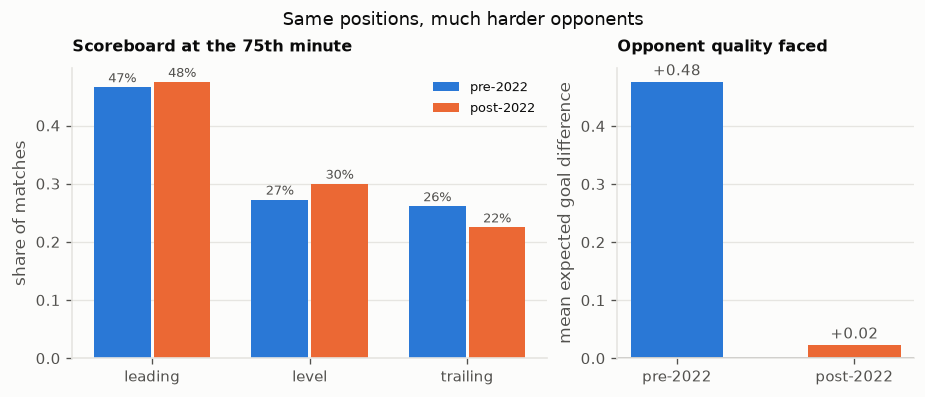

In [22]:
at75 = []
for mid, (tl, _s, _x) in TL.items():
    d75 = sum(d for m_, d in tl if m_ <= 75)
    at75.append({"era": info.loc[mid, "era"],
                 "at75": "leading" if d75 > 0 else ("trailing" if d75 < 0 else "level")})
at75 = pd.DataFrame(at75)

fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.2),
                         gridspec_kw={"width_ratios": [1.6, 1]})
a = axes[0]
sh75 = (pd.crosstab(at75.era, at75.at75, normalize="index")
        .reindex(index=["pre", "post"])[["leading", "level", "trailing"]])
x = np.arange(3)
a.bar(x - 0.19, sh75.loc["pre"], width=0.36, color=viz.BLUE, label="pre-2022")
a.bar(x + 0.19, sh75.loc["post"], width=0.36, color=viz.ORANGE, label="post-2022")
for off, e in ((-0.19, "pre"), (0.19, "post")):
    for xi_, v in zip(x + off, sh75.loc[e]):
        a.annotate(f"{v:.0%}", (xi_, v), xytext=(0, 3), ha="center",
                   textcoords="offset points", fontsize=7.5, color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(sh75.columns)
a.set_ylabel("share of matches")
a.set_title("Scoreboard at the 75th minute", fontsize=9.5)
a.legend(fontsize=8)
viz.despine(a)

b = axes[1]
opp = mt.groupby("era").expected_gd.mean().reindex(["pre", "post"])
b.bar([0, 1], opp.values, width=0.52, color=[viz.BLUE, viz.ORANGE])
for i, v in enumerate(opp.values):
    b.annotate(f"{v:+.2f}", (i, v), xytext=(0, 4), textcoords="offset points",
               ha="center", fontsize=9, color=viz.INK_2)
b.axhline(0, color=viz.INK_2, lw=1.0)
b.set_xticks([0, 1])
b.set_xticklabels(["pre-2022", "post-2022"])
b.set_ylabel("mean expected goal difference")
b.set_title("Opponent quality faced", fontsize=9.5)
viz.despine(b)
fig.suptitle("Same positions, much harder opponents", fontsize=11)
plt.show()

**This is the part that did not improve.**

The shortfall is **−0.50** pre and **−0.41** post, a change of **+0.09, 95%
[−0.36, +0.77]**. The raw conceding rate in that cell rises 3.04 → 7.32 per 90,
alarming until the interval: [−0.08, +11.59]. Ten goals in 123 minutes
distinguishes nothing, so this must **not** be reported as having worsened.

**The scoreboard distribution barely moves either** — Jordan reaches the 75th
minute leading in **47%** of matches in both eras, and level in about a quarter.

🚨 **That is the interesting part.** Over the same period the opposition got much
harder: mean expected goal difference **+0.48 → +0.02**, and among the matches
reaching 75' level, **+0.50 → −0.41**. **Holding the same scoreboard positions
against that much better opposition *is* the improvement** — notebook 02's
headline in another register. The conversion from them did not improve at all.

So Part 3 contributes a negative, and a useful one: **none of the improvement
came from managing tight matches better.**

## Summary

| | | |
|---|---|---|
| **Supported** | the goals came from a narrower group | distinct scorers, top-3 share and HHI all outside the rarefied pre-2022 range |
| | the leading scorers got more minutes **and** got faster | Olwan 1.5% → 7.2% of minutes; Al-Taamari 0.27 → 0.53 per 90 |
| | Jordan concedes late, out of level scorelines | while level 3.92× [1.80, 11.47]; while leading 1.01× [0.45, 2.22] |
| | and those late goals go **one way** | Jordan's share 0.240 [0.048, 0.419] against a model-implied 0.539 |
| **Unchanged** | the late-conceding problem | change +0.09 [−0.36, +0.77] |
| | the scoreboard Jordan reaches at 75' | leading in 47% of matches in both eras |
| **Not established** | dependence on one player | top-1 share sits *inside* the rarefied range |
| | more goals from midfield | +0.146 by team-sheet label, **+0.038** by usual position — retired |
| | penalties flattering the record | 9.9% → 14.3% on 14 and 11 goals |
| **Ruled out** | that the narrowing is about *scoring* | 2.4× more concentrated than minutes imply — the same multiple in both eras |

### So how did the results get better?

**Through the attack, from a narrower group, with a more settled team.** More of
the goals from a small set of players who both played more and scored faster,
minutes concentrated in fewer men, those men having played together more —
against opposition that got substantially harder.

**Not through game management.** Same scoreboard positions at the 75th minute,
converted exactly as badly.

### What this licenses

A **coincidence with uncertainty**, and no more. Squad change, coaching change
and scheduling all move together across mid-2022, about 40 matches follow it, and
no design here separates them. The one thing worth adding beyond the association
is a caution: **a rise carried by a narrow group is more fragile than one carried
by a broad one, and top-3 share is the number to watch** if the level slips.

---

**Next:** notebook 05 takes the two things this notebook could not settle — what
did **not** change, and what was never tested — and asks what Jordan could
actually do next.